# 05 - A/B test: `AdsConfig_iOS`

**Goal.** The data contains one experiment, `AdsConfig_iOS`, with three variants (`Control-Variant`, `Variant-A`, `Variant-B`). Does a variant change retention or ad exposure?

**Reading rule.** The content of each variant is not documented: only its name is known, so results describe *what changed in the data*, not *what the variant was*. With about 1,100 players per variant, only fairly large differences can be detected: a result with an interval that includes 0 means "no difference detected", not "no difference".

In [1]:
import sys
sys.path.append("../scripts")
from load_events import connect_events
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare
from statsmodels.stats.proportion import confint_proportions_2indep

con, readable, unreadable = connect_events("../data/raw/player_analytics/*.parquet")
print(len(readable), "readable files,", len(unreadable), "unreadable")
CONTROL = "Control-Variant"

67 readable files, 1 unreadable


## 1. Who is in the experiment?

One row per player, with the variant of their first join. Players who joined more than once are kept once; the check below shows whether any of them saw two variants (that would contaminate the test).

In [2]:
con.execute("""
    CREATE OR REPLACE TABLE exp_players AS
    SELECT user_id,
           MIN(ts)                                                     AS join_ts,
           CAST(MIN(ts) AS DATE)                                       AS join_day,
           ARG_MIN(event_properties['experiment_variant_name'], ts)    AS variant,
           COUNT(*)                                                    AS joins,
           COUNT(DISTINCT event_properties['experiment_variant_name']) AS variants_seen
    FROM events
    WHERE event_name = '_experimentJoin'
      AND event_properties['experiment_name'] = 'AdsConfig_iOS'
    GROUP BY 1
""")
con.sql("""
    SELECT variant, COUNT(*) AS players, MIN(join_day) AS first_join, MAX(join_day) AS last_join,
           COUNT(*) FILTER (WHERE joins > 1) AS joined_twice,
           COUNT(*) FILTER (WHERE variants_seen > 1) AS saw_two_variants
    FROM exp_players GROUP BY 1 ORDER BY 1
""").show(max_width=200)

┌─────────────────┬─────────┬────────────┬────────────┬──────────────┬──────────────────┐
│     variant     │ players │ first_join │ last_join  │ joined_twice │ saw_two_variants │
│     varchar     │  int64  │    date    │    date    │    int64     │      int64       │
├─────────────────┼─────────┼────────────┼────────────┼──────────────┼──────────────────┤
│ Control-Variant │    1105 │ 2025-03-07 │ 2025-04-10 │           19 │                0 │
│ Variant-A       │    1093 │ 2025-03-07 │ 2025-04-10 │           15 │                0 │
│ Variant-B       │    1131 │ 2025-03-07 │ 2025-04-10 │           16 │                0 │
└─────────────────┴─────────┴────────────┴────────────┴──────────────┴──────────────────┘



In [3]:
con.execute("""
    CREATE OR REPLACE TABLE exp_events AS
    SELECT e.user_id, e.event_name, e.ts, e.user_session_id, e.client_platform, e.country_code,
           e.event_properties['adFormat'] AS ad_format,
           TRY_CAST(REPLACE(REPLACE(COALESCE(e.event_properties['amount'], e.event_properties['value']), ',', '.'), '/', '.') AS DOUBLE) AS amount_usd,
           e.user_properties_custom['appVersion'] AS app_version
    FROM events e
    JOIN exp_players p USING (user_id)
""")
con.sql("SELECT COUNT(*) AS events, COUNT(DISTINCT user_id) AS players FROM exp_events").show()

┌─────────┬─────────┐
│ events  │ players │
│  int64  │  int64  │
├─────────┼─────────┤
│ 3552110 │    3329 │
└─────────┴─────────┘



## 2. Is the split random and balanced?

Three checks: the variant sizes (sample ratio), the platform and country, and the app version at join time. Players should also join at their very first moment in the game.

In [4]:
sizes = con.execute("SELECT variant, COUNT(*) AS n FROM exp_players GROUP BY 1 ORDER BY 1").df()
print(sizes.to_string(index=False))
print("sample ratio check, equal split expected:", chisquare(sizes["n"].values))

con.sql("""
    SELECT p.variant,
           COUNT(DISTINCT p.user_id)                                          AS players,
           COUNT(DISTINCT p.user_id) FILTER (WHERE e.client_platform = 'IPhonePlayer') AS iphone_players,
           COUNT(DISTINCT p.user_id) FILTER (WHERE e.country_code = 'US')      AS us_players
    FROM exp_players p JOIN exp_events e USING (user_id)
    GROUP BY 1 ORDER BY 1
""").show(max_width=200)

        variant    n
Control-Variant 1105
      Variant-A 1093
      Variant-B 1131
sample ratio check, equal split expected: Power_divergenceResult(statistic=np.float64(0.6800841093421448), pvalue=np.float64(0.7117403901252148))
┌─────────────────┬─────────┬────────────────┬────────────┐
│     variant     │ players │ iphone_players │ us_players │
│     varchar     │  int64  │     int64      │   int64    │
├─────────────────┼─────────┼────────────────┼────────────┤
│ Control-Variant │    1105 │           1105 │       1105 │
│ Variant-A       │    1093 │           1093 │       1093 │
│ Variant-B       │    1131 │           1131 │       1131 │
└─────────────────┴─────────┴────────────────┴────────────┘



In [5]:
con.sql("""
    WITH first_event AS (SELECT user_id, MIN(ts) AS t FROM exp_events GROUP BY 1)
    SELECT p.variant,
           ROUND(MEDIAN(epoch(p.join_ts - f.t) / 3600), 2) AS median_hours_after_first_event,
           ROUND(100.0 * COUNT(*) FILTER (WHERE epoch(p.join_ts - f.t) / 3600 > 24) / COUNT(*), 1) AS pct_joined_after_24h
    FROM exp_players p JOIN first_event f USING (user_id)
    GROUP BY 1 ORDER BY 1
""").show(max_width=200)

con.sql("""
    SELECT p.variant, e.app_version, COUNT(DISTINCT p.user_id) AS players
    FROM exp_players p
    JOIN exp_events e ON e.user_id = p.user_id AND CAST(e.ts AS DATE) = p.join_day
    WHERE e.app_version IS NOT NULL
    GROUP BY 1, 2 ORDER BY 1, 3 DESC
""").show(max_rows=12, max_width=200)

┌─────────────────┬────────────────────────────────┬──────────────────────┐
│     variant     │ median_hours_after_first_event │ pct_joined_after_24h │
│     varchar     │             double             │        double        │
├─────────────────┼────────────────────────────────┼──────────────────────┤
│ Control-Variant │                            0.0 │                  0.1 │
│ Variant-A       │                            0.0 │                  0.0 │
│ Variant-B       │                            0.0 │                  0.1 │
└─────────────────┴────────────────────────────────┴──────────────────────┘

┌─────────────────┬─────────────┬─────────┐
│     variant     │ app_version │ players │
│     varchar     │   varchar   │  int64  │
├─────────────────┼─────────────┼─────────┤
│ Control-Variant │ 0.21.21     │     641 │
│ Control-Variant │ 0.21.23     │     468 │
│ Variant-A       │ 0.21.21     │     619 │
│ Variant-A       │ 0.21.23     │     469 │
│ Variant-B       │ 0.21.21     │     6

If the variants differ in size beyond chance (small p-value in the sample ratio check), the assignment is suspect. Here every player has iPhone events and US events in all three variants: the experiment name says iOS, and the platform and country checks give the same result in every group, so neither explains a difference between variants.

## 3. Retention (D1 and D7), counted from the join day

The 2025-03-27 data gap is excluded: a player whose D1 or D7 day is that day is left out of that metric. Difference to control, in percentage points, with a 95% interval (Newcombe).

In [6]:
con.execute("CREATE OR REPLACE TABLE act AS SELECT DISTINCT user_id, CAST(ts AS DATE) AS day FROM exp_events")
LAST_FULL_DAY = "2025-04-09"
rows = []
for n in (1, 7):
    d = con.execute(f"""
        SELECT p.variant, COUNT(*) AS players, COUNT(a.user_id) AS retained
        FROM exp_players p
        LEFT JOIN act a ON a.user_id = p.user_id AND a.day = p.join_day + {n}
        WHERE p.join_day + {n} <= DATE '{LAST_FULL_DAY}' AND p.join_day + {n} <> DATE '2025-03-27'
        GROUP BY 1 ORDER BY 1
    """).df()
    c = d[d["variant"] == CONTROL].iloc[0]
    for _, r in d.iterrows():
        diff = 100 * (r.retained / r.players - c.retained / c.players)
        if r.variant == CONTROL:
            lo = hi = np.nan
        else:
            l, h = confint_proportions_2indep(int(r.retained), int(r.players), int(c.retained), int(c.players), method="newcomb")
            lo, hi = 100 * l, 100 * h
        rows.append(dict(day_n=n, variant=r.variant, players=int(r.players), pct=round(100 * r.retained / r.players, 1),
                         diff_pts=None if r.variant == CONTROL else round(diff, 1),
                         ci_low=None if r.variant == CONTROL else round(lo, 1), ci_high=None if r.variant == CONTROL else round(hi, 1)))
df_ret = pd.DataFrame(rows)
df_ret

,day_n,variant,players,pct,diff_pts,ci_low,ci_high
0,1,Control-Variant,1022,38.3,NaN,NaN,NaN
1,1,Variant-A,1011,38.3,0.0,-4.2,4.2
2,1,Variant-B,1028,39.7,1.4,-2.8,5.6
3,7,Control-Variant,829,6.5,NaN,NaN,NaN
4,7,Variant-A,794,7.3,0.8,-1.7,3.3
5,7,Variant-B,822,7.1,0.5,-1.9,3.0


## 4. Ad exposure and revenue

Per player, on the join day and over the first 7 days (players who joined at least 7 days before the last full day). The interval comes from a bootstrap (3,000 resamples of the players). Revenue is the estimated ad revenue (`amount`, or `value` before the rename); a version capped at 1 USD per impression is shown because a few impressions have extreme values.

In [7]:
con.execute("""
    CREATE OR REPLACE TABLE ads_exp AS
    SELECT user_id, CAST(ts AS DATE) AS day, ad_format, amount_usd
    FROM exp_events WHERE event_name = 'adImpression'
""")

def per_player(offset_end, max_join):
    return con.execute(f"""
        SELECT p.user_id, p.variant,
               COUNT(*) FILTER (WHERE a.ad_format = 'INTER')    AS interstitials,
               COUNT(*) FILTER (WHERE a.ad_format = 'REWARDED') AS rewarded,
               COALESCE(SUM(a.amount_usd), 0)                   AS revenue_usd,
               COALESCE(SUM(LEAST(a.amount_usd, 1)), 0)         AS revenue_capped_usd
        FROM exp_players p
        LEFT JOIN ads_exp a ON a.user_id = p.user_id AND a.day BETWEEN p.join_day AND p.join_day + {offset_end}
        WHERE p.join_day <= DATE '{max_join}' AND p.join_day <> DATE '2025-03-27'
        GROUP BY 1, 2
    """).df()

def compare(df, metrics, n_boot=3000, seed=1):
    rng = np.random.default_rng(seed)
    out = []
    ctrl_all = df[df["variant"] == CONTROL]
    for m in metrics:
        c = ctrl_all[m].values
        out.append(dict(metric=m, variant=CONTROL, players=len(c), mean=round(c.mean(), 3), diff=None, pct_change=None, ci_low=None, ci_high=None))
        for v in sorted(set(df["variant"]) - {CONTROL}):
            x = df[df["variant"] == v][m].values
            diffs = [rng.choice(x, len(x)).mean() - rng.choice(c, len(c)).mean() for _ in range(n_boot)]
            lo, hi = np.percentile(diffs, [2.5, 97.5])
            out.append(dict(metric=m, variant=v, players=len(x), mean=round(x.mean(), 3), diff=round(x.mean() - c.mean(), 3),
                            pct_change=round(100 * (x.mean() / c.mean() - 1), 1), ci_low=round(lo, 3), ci_high=round(hi, 3)))
    return pd.DataFrame(out)

METRICS = ["interstitials", "rewarded", "revenue_usd", "revenue_capped_usd"]
day0 = per_player(0, LAST_FULL_DAY)
res_day0 = compare(day0, METRICS)
res_day0

,metric,variant,players,mean,diff,pct_change,ci_low,ci_high
0,interstitials,Control-Variant,1077,7.516,NaN,NaN,NaN,NaN
1,interstitials,Variant-A,1056,7.940,0.424,5.6,-0.626,1.532
2,interstitials,Variant-B,1102,6.046,-1.470,-19.6,-2.422,-0.526
3,rewarded,Control-Variant,1077,4.373,NaN,NaN,NaN,NaN
4,rewarded,Variant-A,1056,4.003,-0.370,-8.5,-1.097,0.338
5,rewarded,Variant-B,1102,4.384,0.011,0.2,-0.862,0.903
6,revenue_usd,Control-Variant,1077,0.952,NaN,NaN,NaN,NaN
7,revenue_usd,Variant-A,1056,0.943,-0.009,-0.9,-0.235,0.228
8,revenue_usd,Variant-B,1102,0.874,-0.078,-8.2,-0.293,0.160
9,revenue_capped_usd,Control-Variant,1077,0.942,NaN,NaN,NaN,NaN


In [8]:
week = per_player(6, "2025-04-03")
res_week = compare(week, METRICS)
res_week

,metric,variant,players,mean,diff,pct_change,ci_low,ci_high
0,interstitials,Control-Variant,876,14.362,NaN,NaN,NaN,NaN
1,interstitials,Variant-A,840,14.537,0.175,1.2,-2.333,2.793
2,interstitials,Variant-B,873,13.042,-1.319,-9.2,-3.885,1.263
3,rewarded,Control-Variant,876,7.927,NaN,NaN,NaN,NaN
4,rewarded,Variant-A,840,8.436,0.509,6.4,-2.317,4.410
5,rewarded,Variant-B,873,9.283,1.356,17.1,-0.938,3.712
6,revenue_usd,Control-Variant,876,1.286,NaN,NaN,NaN,NaN
7,revenue_usd,Variant-A,840,1.380,0.095,7.4,-0.190,0.408
8,revenue_usd,Variant-B,873,1.257,-0.028,-2.2,-0.327,0.269
9,revenue_capped_usd,Control-Variant,876,1.249,NaN,NaN,NaN,NaN


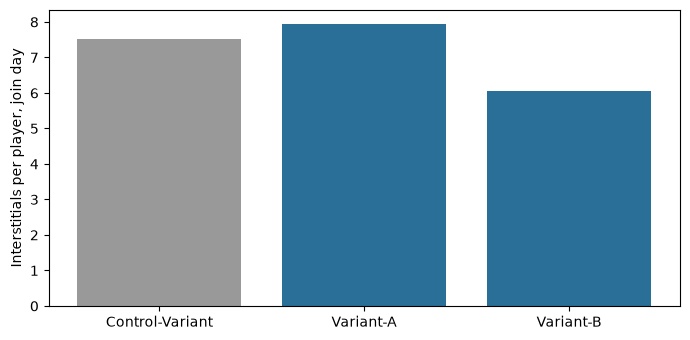

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
d = res_day0[res_day0["metric"] == "interstitials"]
ax.bar(d["variant"], d["mean"], color=["#999999", "#2a6f97", "#2a6f97"])
ax.set_ylabel("Interstitials per player, join day")
plt.tight_layout()
plt.show()

A difference is *detected* only if its interval excludes 0. Several metrics are tested here (4 metrics, 2 variants, 2 windows): with so many comparisons, one interval can exclude 0 by chance, so a single borderline result should not be over-read.

## 5. Purchases cannot be compared

`purchaseCompleted` and `inAppPurchase` only appear for Android players (store `GooglePlay`): no purchase of these iPhone players is visible there, so purchase rate is not an outcome of this test. Product-named events (`starterPack`, ...) also exist for iPhone players, but their meaning is not documented.

In [10]:
con.sql("""
    SELECT event_name, COUNT(*) AS events, COUNT(DISTINCT user_id) AS players
    FROM exp_events
    WHERE event_name IN ('purchaseCompleted', 'inAppPurchase', 'starterPack', 'superStarterPack', 'noAds24Hours', 'noAds')
    GROUP BY 1 ORDER BY 2 DESC
""").show()

┌──────────────────┬────────┬─────────┐
│    event_name    │ events │ players │
│     varchar      │ int64  │  int64  │
├──────────────────┼────────┼─────────┤
│ starterPack      │     94 │      90 │
│ superStarterPack │     32 │      31 │
│ noAds            │      7 │       7 │
│ noAds24Hours     │      2 │       2 │
└──────────────────┴────────┴─────────┘



## 6. How many players would a conclusive test need?

Power analysis for D1, with the control's 38.3% as baseline: the number of players per variant needed to detect a 2-point change with 80% power, and the smallest difference the current test (about 1,000 players per variant) could detect.

In [11]:
import math
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline = 0.383          # D1 of the control group (section 3)
analysis = NormalIndPower()

# 1. Players per variant needed to detect +2 points of D1 with 80% power
for alpha, label in [(0.05, "one variant against control"),
                     (0.025, "two variants against control (Bonferroni, alpha = 0.025)")]:
    effect = proportion_effectsize(baseline + 0.02, baseline)
    n = analysis.solve_power(effect_size=effect, alpha=alpha, power=0.8)
    print(f"+2 points, {label}: {math.ceil(n):,} players per variant")

# 2. Smallest D1 difference this test could detect (80% power) with about 1,000 players per variant
h = analysis.solve_power(nobs1=1000, alpha=0.05, power=0.8)
mde = math.sin(math.asin(math.sqrt(baseline)) + h / 2) ** 2 - baseline
print(f"Minimum detectable effect with 1,000 players per variant: {100 * mde:.1f} points")

+2 points, one variant against control: 9,361 players per variant
+2 points, two variants against control (Bonferroni, alpha = 0.025): 11,336 players per variant
Minimum detectable effect with 1,000 players per variant: 6.2 points


## Findings

- **The experiment.** `AdsConfig_iOS`, three variants: `Control-Variant` (1,105 players), `Variant-A` (1,093) and `Variant-B` (1,131), from 2025-03-07 to 2025-04-10. All are iPhone players, joined at their very first moment in the game, and all have activity in the US. The split looks random: the sample ratio check gives p = 0.71 (no sign of a biased assignment), the share of app versions is similar in the three groups, and no player saw two variants.
- **Retention: no difference detected.** D1 is 38.3% (control), 38.3% (A) and 39.7% (B); the differences to control are 0.0 (interval -4.2 to +4.2) and +1.4 points (-2.8 to +5.6). D7 is 6.5%, 7.3% and 7.1%; differences +0.8 (-1.7 to +3.3) and +0.5 (-1.9 to +3.0). With about 1,000 players per variant, the smallest D1 difference this test could detect with 80% power is about 6 points (section 6): smaller effects would usually go unseen.
- **Ad exposure: Variant B shows fewer interstitials on the first day.** 6.0 interstitials per player against 7.5 in control (-19.6%, interval -2.4 to -0.6 per player: it excludes 0). Variant A is close to control (+5.6%, interval -0.6 to +1.6). Rewarded videos and estimated ad revenue show no detectable difference on the first day, and over the first 7 days no interval excludes 0 (B: -1.3 interstitials per player, interval -3.8 to +1.1).
- **Reading.** Variant B appears to reduce early interstitial exposure without a visible effect on D1, D7 or estimated revenue, but the test cannot rule out moderate effects on those. What each variant changed is not documented. Given the number of comparisons (4 metrics, 2 variants, 2 windows), the interstitial result is a lead to confirm, not a proof.
- **A conclusive test needs about ten times more players.** Detecting a 2-point change of D1 with 80% power needs 9,361 players per variant, or 11,336 when two variants are compared with the control (Bonferroni).
- **Purchases are not measurable here.** `purchaseCompleted` and `inAppPurchase` only occur for Android players; the iPhone players of this test have none of them.

**Limits.**
- The content of the variants is unknown.
- About 1,100 players per variant: small effects cannot be seen.
- iPhone players in the US only: the result does not transfer to Android or other countries.
- Purchases are not measurable for this population.